# Projet 8 — Les Plus Beaux Logis de Paris
## Analyse historique et valorisation du portefeuille

**Steve Bell · octobre 2026**

Ce notebook couvre l’analyse historique 2017–2021, l’évaluation chronologique d’une régression linéaire, l’estimation du portefeuille au 31 décembre 2022 et un essai de classement K-means sur l’échantillon transmis par OpenClassrooms.

**Fichiers utilisés :** les classeurs d’historique et de portefeuille ainsi que `echantillon_a_classer2.xlsx`, dans `data/raw/`. L’échantillon contient 40 opportunités. Les étiquettes de référence de l’équipe de Louise ne sont pas disponibles : la comparaison officielle reste à faire.

> Les estimations sont des résultats statistiques pédagogiques, pas une expertise immobilière ni une décision d’achat.


## tl;dr
Le résumé ci-dessous est calculé à l’exécution; les graphiques, tables et contrôles intermédiaires permettent d’en vérifier la provenance.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, silhouette_score

candidats_racine = (Path.cwd().resolve(), Path.cwd().resolve().parent)
PROJECT_ROOT = next(
    (dossier for dossier in candidats_racine
     if (dossier / "data" / "raw").is_dir() and (dossier / "livrables").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Ouvrez le notebook depuis la racine du projet ou son dossier livrables.")
DATA_DIR = PROJECT_ROOT / "data" / "raw"
OUT_DIR = PROJECT_ROOT / "livrables"
FIGURES_DIR = OUT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Import et profil des données

In [2]:
historique_brut = pd.read_excel(DATA_DIR / "historique_immobilier_paris_2017_2021.xlsx")
portefeuille = pd.read_excel(DATA_DIR / "portefeuille_actifs.xlsx")
historique_brut.head()

,date_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,code_postal,nom_commune,code_type_local,type_local,surface_reelle
0,2017-01-03,"550,559.68",8,RUE DES COUTURES SAINT GERVAIS,75003,Paris 3e Arrondissement,2,Appartement,50
1,2017-01-12,"1,576,492.46",32,AV MARCEAU,75008,Paris 8e Arrondissement,2,Appartement,163
2,2017-01-10,"657,757.36",52,RUE DU FAUBOURG SAINT HONORE,75008,Paris 8e Arrondissement,2,Appartement,66
3,2017-01-10,"250,086.82",64,RUE DU VERTBOIS,75003,Paris 3e Arrondissement,2,Appartement,22
4,2017-01-13,"176,266.71",25,RUE DES LAVANDIERES STE OPPORT,75001,Paris 1er Arrondissement,2,Appartement,15


In [3]:
print("Dimensions :", historique_brut.shape)
print("Types de colonnes :")
display(historique_brut.dtypes.to_frame("type Pandas"))
print("\nValeurs manquantes :")
display(historique_brut.isna().sum().to_frame("manquantes"))
print("Lignes entièrement identiques :", historique_brut.duplicated().sum())

Dimensions : (26196, 9)
Types de colonnes :

Valeurs manquantes :
Lignes entièrement identiques : 16


,type Pandas
date_mutation,datetime64[ns]
valeur_fonciere,float64
adresse_numero,int64
adresse_nom_voie,object
code_postal,int64
nom_commune,object
code_type_local,int64
type_local,object
surface_reelle,int64


,manquantes
date_mutation,0
valeur_fonciere,0
adresse_numero,0
adresse_nom_voie,0
code_postal,0
nom_commune,0
code_type_local,0
type_local,0
surface_reelle,0


**Contrôle de qualité.** Les colonnes de date sont au format date, le prix foncier est numérique, et le type/adresse sont catégoriels. Il n’y a pas de valeur manquante dans l’historique fourni. 16 lignes sont strictement identiques sur les neuf colonnes; faute d’identifiant de transaction pour déterminer s’il s’agit d’un doublon technique ou de mutations distinctes, elles sont conservées et leur présence est signalée.

In [4]:
historique = historique_brut.copy()
historique["date_mutation"] = pd.to_datetime(historique["date_mutation"], errors="coerce")
historique["prix_m2"] = historique["valeur_fonciere"] / historique["surface_reelle"]
historique["annee"] = historique["date_mutation"].dt.year
historique["date_annees"] = (historique["date_mutation"] - pd.Timestamp("2017-01-01")).dt.days / 365.25
assert historique["date_mutation"].notna().all()
assert (historique["surface_reelle"] > 0).all()
assert (historique["valeur_fonciere"] > 0).all()
historique[["date_mutation", "valeur_fonciere", "surface_reelle", "prix_m2", "type_local"]].head()

,date_mutation,valeur_fonciere,surface_reelle,prix_m2,type_local
0,2017-01-03,"550,559.68",50,"11,011.19",Appartement
1,2017-01-12,"1,576,492.46",163,"9,671.73",Appartement
2,2017-01-10,"657,757.36",66,"9,966.02",Appartement
3,2017-01-10,"250,086.82",22,"11,367.58",Appartement
4,2017-01-13,"176,266.71",15,"11,751.11",Appartement


## 2–4. Types de biens, volumes et période

In [5]:
print("Types de biens et codes :")
display(historique.groupby(["code_type_local", "type_local"], as_index=False).size().rename(columns={"size":"nombre de lignes"}))
print(f"Nombre total de lignes / transactions représentées : {len(historique):,}")
display(historique["type_local"].value_counts().rename_axis("type de bien").to_frame("transactions"))
print("Période :", historique.date_mutation.min().date(), "à", historique.date_mutation.max().date())

Types de biens et codes :
Nombre total de lignes / transactions représentées : 26,196
Période : 2017-01-02 à 2021-12-31


,code_type_local,type_local,nombre de lignes
0,2,Appartement,24353
1,4,Local industriel. commercial ou assimilé,1843


,transactions
type de bien,
Appartement,24353
Local industriel. commercial ou assimilé,1843


Les lignes du fichier sont utilisées comme transactions faute d’identifiant de vente distinct. Le fichier couvre Paris et contient les types Appartement et Local industriel, commercial ou assimilé. Les décomptes incluent les 16 lignes identiques signalées plus haut.

## 5. Évolution du prix moyen au m² des appartements

Variation de la moyenne 2017–2021 : 10.1%


,moyenne,mediane,transactions
annee,,,
2017,"9,492.86","9,167.49",5206
2018,"10,031.40","9,643.75",5076
2019,"10,562.71","10,197.72",5251
2020,"10,674.87","10,304.25",4127
2021,"10,455.60","10,164.82",4693


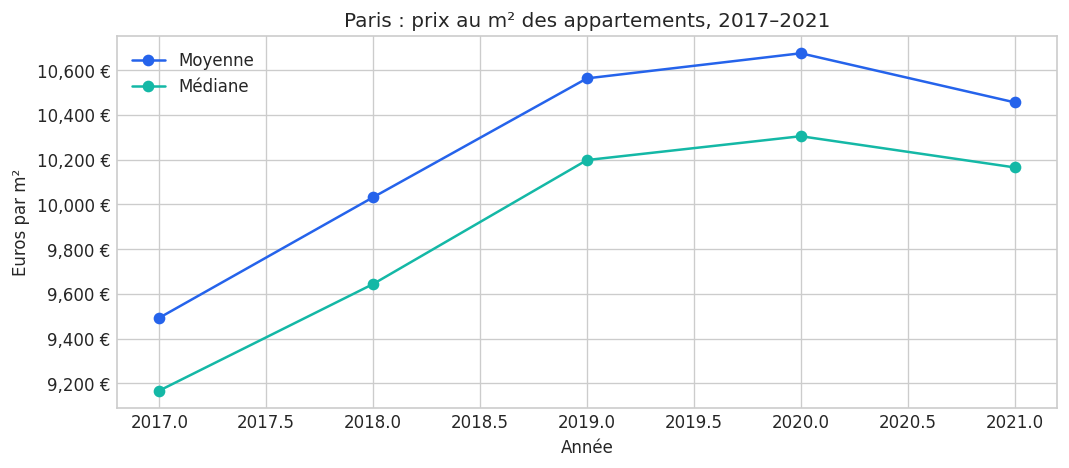

In [6]:
appartements = historique.loc[historique.type_local.eq("Appartement")].copy()
prix_annuel = appartements.groupby("annee")["prix_m2"].agg(moyenne="mean", mediane="median", transactions="size")
display(prix_annuel)
variation_17_21 = (prix_annuel.loc[2021,"moyenne"] / prix_annuel.loc[2017,"moyenne"] - 1) * 100
print(f"Variation de la moyenne 2017–2021 : {variation_17_21:.1f}%")
ax = prix_annuel[["moyenne", "mediane"]].plot(marker="o", figsize=(9,4), color=["#2563eb", "#14b8a6"])
ax.set(title="Paris : prix au m² des appartements, 2017–2021", xlabel="Année", ylabel="Euros par m²")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f} €")); ax.legend(["Moyenne", "Médiane"], frameon=False); plt.tight_layout(); plt.savefig(FIGURES_DIR / "evolution_prix_m2.png", dpi=160, bbox_inches="tight"); plt.show()

La moyenne progresse de 2017 à 2020, puis recule légèrement en 2021. Le changement entre première et dernière année compare des moyennes de transactions et n’est pas corrigé de l’inflation ni de la composition des biens vendus.

## 6. Différences entre arrondissements

Moyenne 2021 — cinq arrondissements les plus élevés :
Moyenne 2021 — cinq arrondissements les plus bas :


annee,2017,2018,2019,2020,2021
code_postal,,,,,
75001,11763,12621,13269,13406,13379
75002,10920,11309,12151,12182,11773
75003,11680,12470,12813,12834,12661
75004,12407,13432,13641,13105,12937
75005,11307,12056,12928,12960,12606
75006,12509,12896,13378,13807,13795
75007,11845,12553,12922,13110,13118
75008,10133,10631,11195,11703,11710
75009,9582,10187,10958,10981,10732


,"€/m², 2021"
code_postal,
75006,"13,795.05"
75001,"13,379.50"
75007,"13,118.14"
75004,"12,936.96"
75003,"12,660.55"


,"€/m², 2021"
code_postal,
75019,"8,828.59"
75020,"9,114.40"
75013,"9,164.63"
75012,"9,657.98"
75018,"9,665.64"


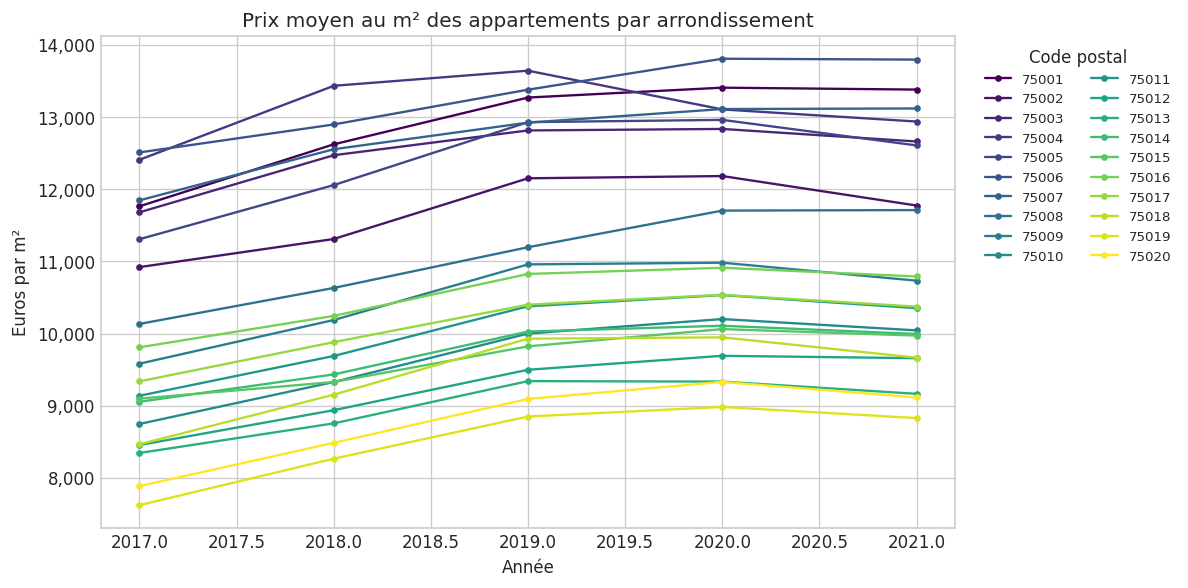

In [7]:
prix_arrondissement = appartements.pivot_table(index="code_postal", columns="annee", values="prix_m2", aggfunc="mean")
display(prix_arrondissement.round(0).astype("Int64"))
ax = prix_arrondissement.T.plot(figsize=(10,5), marker=".", linewidth=1.4, colormap="viridis")
ax.set(title="Prix moyen au m² des appartements par arrondissement", xlabel="Année", ylabel="Euros par m²")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}")); ax.legend(title="Code postal", bbox_to_anchor=(1.02,1), loc="upper left", ncol=2, fontsize=8); plt.tight_layout(); plt.savefig(FIGURES_DIR / "prix_par_arrondissement.png", dpi=160, bbox_inches="tight"); plt.show()
print("Moyenne 2021 — cinq arrondissements les plus élevés :")
display(prix_arrondissement[2021].sort_values(ascending=False).head(5).rename("€/m², 2021").to_frame())
print("Moyenne 2021 — cinq arrondissements les plus bas :")
display(prix_arrondissement[2021].sort_values().head(5).rename("€/m², 2021").to_frame())

Les moyennes par arrondissement montrent des écarts géographiques nets. Elles restent sensibles à la taille et au type des biens vendus chaque année; elles ne contrôlent pas les caractéristiques individuelles des logements.

## 7. Prix par transaction dans le 6e arrondissement

Transactions d’appartements dans le 6e : 709


,prix au m²
count,709.00
mean,"13,143.51"
std,565.78
min,"12,065.24"
25%,"12,647.67"
50%,"13,122.73"
75%,"13,631.59"
max,"14,169.82"


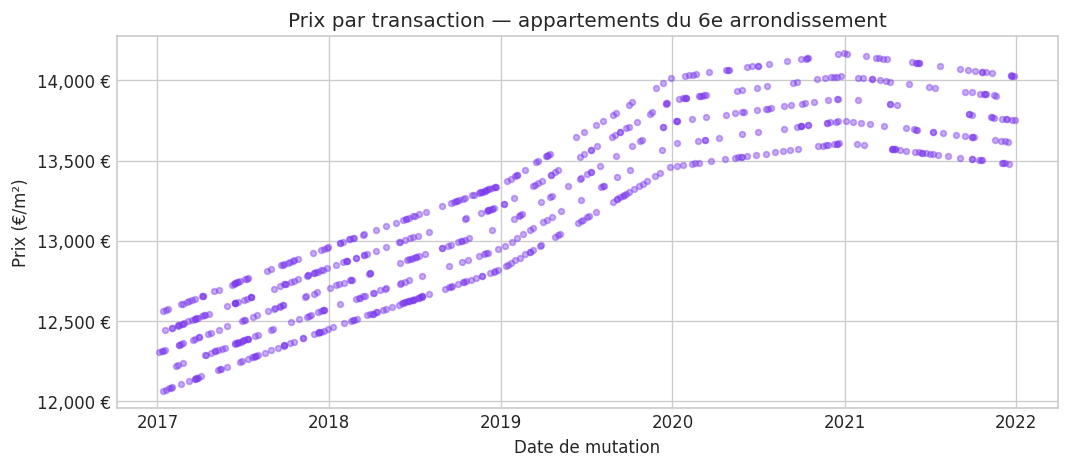

In [8]:
transactions_75006 = appartements.loc[appartements.code_postal.eq(75006)]
print("Transactions d’appartements dans le 6e :", len(transactions_75006))
display(transactions_75006["prix_m2"].describe().to_frame("prix au m²"))
plt.figure(figsize=(9,4)); plt.scatter(transactions_75006.date_mutation, transactions_75006.prix_m2, s=12, alpha=.42, color="#7c3aed")
plt.title("Prix par transaction — appartements du 6e arrondissement")
plt.xlabel("Date de mutation"); plt.ylabel("Prix (€/m²)"); plt.gca().yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f} €")); plt.tight_layout(); plt.savefig(FIGURES_DIR / "transactions_75006.png", dpi=160, bbox_inches="tight"); plt.show()

Le nuage de points permet de voir les dispersions transaction par transaction, les tendances temporelles et d’éventuelles valeurs extrêmes. Le 6e arrondissement est retenu comme exemple, conformément au notebook modèle.

## 8. Corrélation entre prix au m² et date

In [9]:
r_date, p_date = pearsonr(historique["prix_m2"], historique["date_annees"])
print(f"Pearson r = {r_date:.3f} ; p-value {'< 0,001' if p_date < 0.001 else f'= {p_date:.3f}'} ; n = {len(historique):,}")

Pearson r = 0.267 ; p-value < 0,001 ; n = 26,196


La corrélation linéaire est positive, mais sa taille doit guider le commentaire : elle décrit une association moyenne sur l’ensemble des ventes, pas un effet causal du temps. Les changements de composition des biens et les tendances non linéaires ne sont pas contrôlés par ce coefficient.

## 9. Corrélation entre prix au m² et surface

Pearson r = 0.103 ; p-value < 0,001 ; n = 26,196


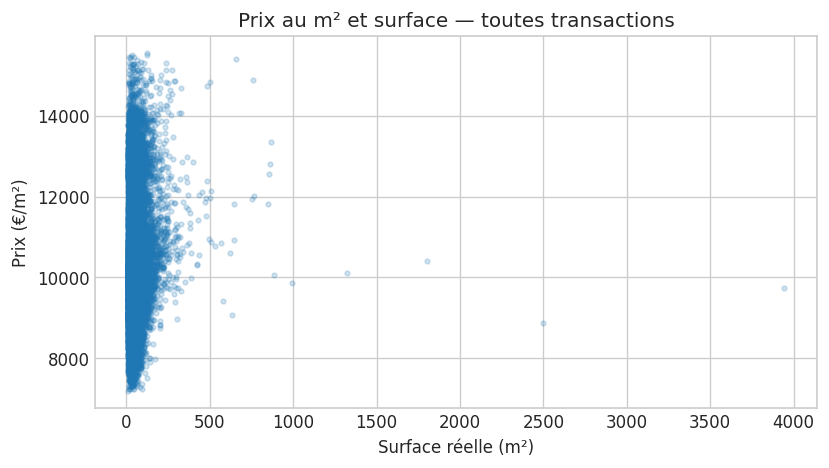

In [10]:
r_surface, p_surface = pearsonr(historique["prix_m2"], historique["surface_reelle"])
print(f"Pearson r = {r_surface:.3f} ; p-value {'< 0,001' if p_surface < 0.001 else f'= {p_surface:.3f}'} ; n = {len(historique):,}")
plt.figure(figsize=(7,4)); plt.scatter(historique.surface_reelle, historique.prix_m2, s=8, alpha=.2)
plt.title("Prix au m² et surface — toutes transactions"); plt.xlabel("Surface réelle (m²)"); plt.ylabel("Prix (€/m²)"); plt.tight_layout(); plt.savefig(FIGURES_DIR / "correlation_surface_prix_m2.png", dpi=160, bbox_inches="tight"); plt.show()

Une valeur p très faible est favorisée par le grand nombre de lignes; le coefficient r renseigne sur l’intensité de l’association. Le prix total et le prix au m² sont deux mesures différentes : la modélisation ci-dessous estime d’abord le prix au m² puis le multiplie par la surface.

## 10. Comparaison des types de biens

Écart de moyenne locaux vs appartements : 14.5%


,moyenne,mediane,transactions
type_local,,,
Appartement,"10,221.63","9,962.34",24353
Local industriel. commercial ou assimilé,"11,705.02","11,322.01",1843


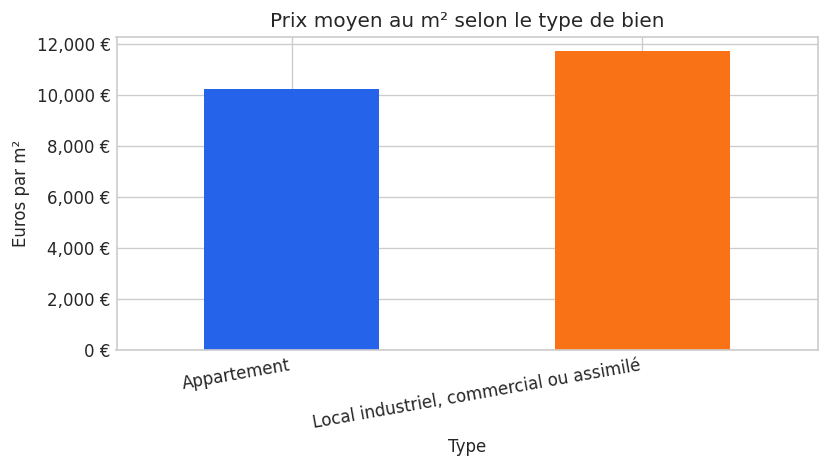

In [11]:
comparaison_types = historique.groupby("type_local")["prix_m2"].agg(moyenne="mean", mediane="median", transactions="size")
display(comparaison_types)
locaux = historique.loc[historique.type_local.ne("Appartement"), "prix_m2"].mean()
apt_moy = historique.loc[historique.type_local.eq("Appartement"), "prix_m2"].mean()
print(f"Écart de moyenne locaux vs appartements : {(locaux/apt_moy-1)*100:.1f}%")
ax = comparaison_types["moyenne"].plot.bar(figsize=(7,4), color=["#2563eb", "#f97316"])
ax.set(title="Prix moyen au m² selon le type de bien", xlabel="Type", ylabel="Euros par m²")
ax.set_xticklabels(["Appartement", "Local industriel, commercial ou assimilé"], rotation=10, ha="right")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f} €")); plt.tight_layout(); plt.savefig(FIGURES_DIR / "comparaison_types.png", dpi=160, bbox_inches="tight"); plt.show()

Dans cet historique, les locaux commerciaux et assimilés affichent une moyenne €/m² supérieure à celle des appartements. Ce constat descriptif ne tient pas compte des différences d’usage, de surface et de localisation.

## Modèle de régression linéaire : test chronologique

### Choix de la cible et des variables
La cible est le logarithme du prix au m². Les variables explicatives sont la date numérique, la surface réelle, le code postal et le type de bien; les variables catégorielles sont transformées par one-hot encoding. La prédiction du prix total s’obtient ensuite par `prix_m2_prédit × surface`. Cette formulation respecte la relation comptable entre prix au m² et valeur totale et évite de confondre l’effet d’échelle de la surface avec le niveau de prix unitaire.

Le découpage est manuel et chronologique : 2017–2020 pour l’apprentissage, 2021 pour le test. Il respecte l’ordre temporel demandé. La métrique principale est la moyenne des erreurs absolues relatives, calculée ligne par ligne, puis exprimée en pourcentage.

In [12]:
features = ["date_annees", "surface_reelle", "code_postal", "type_local"]
categoricals = ["code_postal", "type_local"]
mask_train = historique["date_mutation"] < pd.Timestamp("2021-01-01")
mask_test = ~mask_train

# Le jeu de test n'intervient pas dans la construction des colonnes one-hot.
X_train = pd.get_dummies(historique.loc[mask_train, features], columns=categoricals, dtype=float)
X_test = pd.get_dummies(historique.loc[mask_test, features], columns=categoricals, dtype=float)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
y_train = np.log(historique.loc[mask_train, "prix_m2"])
y_test_total = historique.loc[mask_test, "valeur_fonciere"]

print("Apprentissage :", mask_train.sum(), "lignes jusqu’au", historique.loc[mask_train,"date_mutation"].max().date())
print("Test :", mask_test.sum(), "lignes à partir du", historique.loc[mask_test,"date_mutation"].min().date())

Apprentissage : 21128 lignes jusqu’au 2020-12-31
Test : 5068 lignes à partir du 2021-01-04


In [13]:
modele = LinearRegression()
modele.fit(X_train, y_train)
prediction_test_m2 = np.exp(modele.predict(X_test))
prediction_test_total = prediction_test_m2 * historique.loc[mask_test, "surface_reelle"].to_numpy()
valeurs_reelles_test = y_test_total.to_numpy()
ape_test = np.abs(prediction_test_total - valeurs_reelles_test) / valeurs_reelles_test
mape = ape_test.mean() * 100
mae = mean_absolute_error(valeurs_reelles_test, prediction_test_total)
rmse = mean_squared_error(valeurs_reelles_test, prediction_test_total) ** 0.5
r2 = r2_score(valeurs_reelles_test, prediction_test_total)
biais_pct = np.mean((prediction_test_total - valeurs_reelles_test) / valeurs_reelles_test) * 100
print(f"Erreur absolue relative moyenne (test 2021) : {mape:.2f}%")
print(f"MAE : {mae:,.0f} € | RMSE : {rmse:,.0f} € | R² : {r2:.4f} | biais relatif moyen : {biais_pct:+.2f}%")
print("Médiane des erreurs absolues relatives :", f"{np.median(ape_test)*100:.2f}%")

Erreur absolue relative moyenne (test 2021) : 7.87%
MAE : 40,009 € | RMSE : 64,111 € | R² : 0.9885 | biais relatif moyen : +7.86%
Médiane des erreurs absolues relatives : 7.90%


### Lecture critique du modèle
Sur le test chronologique 2021, l’erreur absolue relative moyenne est inférieure à 10 %, mais le biais relatif moyen est positif : le modèle surestime les ventes en moyenne. L’erreur relative est sensible aux petites valeurs; MAE et RMSE complètent la lecture. Les données ne décrivent pas l’état, l’étage, le DPE, la copropriété ni la nature détaillée des locaux. Le score de 2021 ne garantit pas la précision sur le portefeuille en 2022.

## Valorisation du portefeuille au 31 décembre 2022

In [14]:
portefeuille["surface_reelle"] = portefeuille["surface_reelle_bati"]
portefeuille["date_annees"] = (pd.Timestamp("2022-12-31") - pd.Timestamp("2017-01-01")).days / 365.25
X_portefeuille = pd.get_dummies(portefeuille[features], columns=categoricals, dtype=float)
X_portefeuille = X_portefeuille.reindex(columns=X_train.columns, fill_value=0)
portefeuille["prix_m2_estime"] = np.exp(modele.predict(X_portefeuille))
portefeuille["valeur_estimee_2022_12_31"] = portefeuille["prix_m2_estime"] * portefeuille["surface_reelle"]
portefeuille.insert(0, "id_bien", np.arange(1, len(portefeuille)+1))
resume_portefeuille = portefeuille.groupby("type_local").agg(nombre_de_biens=("id_bien","count"),surface_totale_m2=("surface_reelle","sum"),valeur_estimee_euros=("valeur_estimee_2022_12_31","sum"))
display(resume_portefeuille)
print(f"Valorisation totale estimée : {portefeuille.valeur_estimee_2022_12_31.sum():,.0f} €")

Valorisation totale estimée : 180,358,088 €


,nombre_de_biens,surface_totale_m2,valeur_estimee_euros
type_local,,,
Appartement,154,6286,"74,566,946.80"
Local industriel. commercial ou assimilé,121,7696,"105,791,140.86"


Le fichier du portefeuille ne contient pas de variable de branche ou de segment commercial. Le tableau ventile donc la valorisation selon le type de bien (appartement / local industriel, commercial ou assimilé), qui ne doit pas être présenté comme un découpage organisationnel de l’entreprise.

Le modèle utilise `surface_reelle_bati` comme surface réelle, conformément à la note du modèle de code. La colonne `surface_carrez` n’est pas substituée.

In [15]:
sortie_csv = OUT_DIR / "predictions_valorisation_portefeuille_2022-12-31.csv"
colonnes_export = ["id_bien", "adresse_numero", "adresse_nom_voie", "code_postal", "nom_commune", "type_local", "surface_reelle_bati", "prix_m2_estime", "valeur_estimee_2022_12_31"]
portefeuille[colonnes_export].to_csv(sortie_csv, index=False, encoding="utf-8-sig", float_format="%.2f")
print("CSV exporté :", sortie_csv, "—", len(portefeuille), "biens")
portefeuille[colonnes_export].head()

CSV exporté : /workspace/scratch/965f9a42334e/p8-review/livrables/predictions_valorisation_portefeuille_2022-12-31.csv — 275 biens


,id_bien,adresse_numero,adresse_nom_voie,code_postal,nom_commune,type_local,surface_reelle_bati,prix_m2_estime,valeur_estimee_2022_12_31
0,1,127,RUE SAINT-DENIS,75001,Paris 1er Arrondissement,Appartement,25,"15,264.84","381,621.08"
1,2,62,RUE NOTRE-DAME DE NAZARETH,75003,Paris 3e Arrondissement,Appartement,22,"14,886.62","327,505.69"
2,3,62,RUE DE TURENNE,75003,Paris 3e Arrondissement,Appartement,65,"14,884.84","967,514.64"
3,4,32,AV GEORGE V,75008,Paris 8e Arrondissement,Appartement,74,"13,008.63","962,638.82"
4,5,152,BD HAUSSMANN,75008,Paris 8e Arrondissement,Appartement,22,"13,010.52","286,231.35"


## Classification non supervisée avec K-means

Pour simuler le tri des opportunités, K-means est ajusté sans le type de bien et sur le seul prix au m² des transactions 2017–2020. Après l’ajustement, les types connus de cette période servent à donner un nom aux deux groupes. Les transactions de 2021 restent à part pour évaluer le résultat. Ce test historique ne remplace pas la comparaison avec les étiquettes de référence de Louise.

In [16]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=20)
kmeans.fit(historique.loc[mask_train, ["prix_m2"]])
clusters_train = pd.Series(kmeans.labels_, index=historique.index[mask_train], name="cluster")
taux_locaux = pd.crosstab(clusters_train, historique.loc[mask_train, "type_local"], normalize="index")
display(taux_locaux)
classe_local = taux_locaux["Local industriel. commercial ou assimilé"].idxmax()
print("Centres des groupes (€/m²) :", np.round(kmeans.cluster_centers_.ravel(), 0))
print("Groupe interprété comme ‘local commercial’, selon les étiquettes d’apprentissage :", classe_local)

Centres des groupes (€/m²) : [ 9583. 12426.]
Groupe interprété comme ‘local commercial’, selon les étiquettes d’apprentissage : 1


type_local,Appartement,Local industriel. commercial ou assimilé
cluster,,
0,0.96,0.04
1,0.83,0.17


Exactitude globale : 80.1%; équilibrée : 77.1%
Locaux — précision : 23.3%; rappel : 73.6%; F1 : 35.3%
Silhouette : 0.693; référence ‘tout appartement’ : 92.6%


Type prédit,Appartement,Local industriel. commercial ou assimilé
Type réel 2021,,
Appartement,3782,911
Local industriel. commercial ou assimilé,99,276


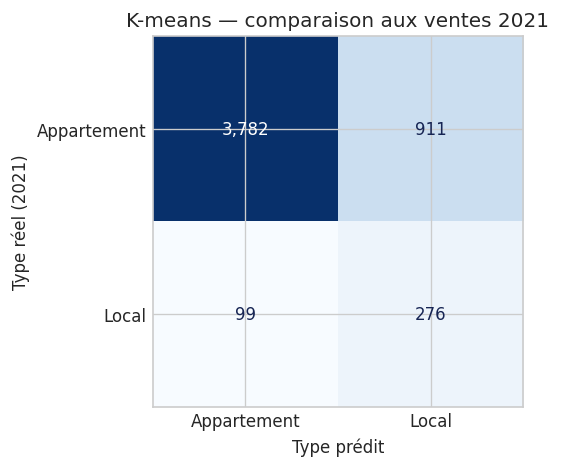

In [17]:
clusters_test = kmeans.predict(historique.loc[mask_test, ["prix_m2"]])
classe_predite = np.where(clusters_test == classe_local, "Local industriel. commercial ou assimilé", "Appartement")
classe_reelle = historique.loc[mask_test, "type_local"].to_numpy()
matrice = pd.crosstab(pd.Series(classe_reelle, name="Type réel 2021"), pd.Series(classe_predite, name="Type prédit"))
ordre_types = ["Appartement", "Local industriel. commercial ou assimilé"]
matrice = matrice.reindex(index=ordre_types, columns=ordre_types, fill_value=0)
display(matrice)
precision_local = precision_score(classe_reelle, classe_predite, pos_label="Local industriel. commercial ou assimilé", zero_division=0)
rappel_local = recall_score(classe_reelle, classe_predite, pos_label="Local industriel. commercial ou assimilé", zero_division=0)
f1_local = f1_score(classe_reelle, classe_predite, pos_label="Local industriel. commercial ou assimilé", zero_division=0)
exactitude = accuracy_score(classe_reelle, classe_predite)
exactitude_equilibree = balanced_accuracy_score(classe_reelle, classe_predite)
score_silhouette = silhouette_score(historique.loc[mask_test, ["prix_m2"]], clusters_test)
reference_majoritaire = pd.Series(classe_reelle).value_counts(normalize=True).max()
print(f"Exactitude globale : {exactitude:.1%}; équilibrée : {exactitude_equilibree:.1%}")
print(f"Locaux — précision : {precision_local:.1%}; rappel : {rappel_local:.1%}; F1 : {f1_local:.1%}")
print(f"Silhouette : {score_silhouette:.3f}; référence ‘tout appartement’ : {reference_majoritaire:.1%}")

fig, ax = plt.subplots(figsize=(6, 4))
image = ax.imshow(matrice.values, cmap="Blues")
ax.set_xticks(range(2), ["Appartement", "Local"])
ax.set_yticks(range(2), ["Appartement", "Local"])
ax.set_xlabel("Type prédit")
ax.set_ylabel("Type réel (2021)")
ax.set_title("K-means — comparaison aux ventes 2021")
for ligne in range(2):
    for colonne in range(2):
        ax.text(colonne, ligne, f"{matrice.iloc[ligne, colonne]:,}", ha="center", va="center",
                color="white" if matrice.iloc[ligne, colonne] > matrice.values.max() / 2 else "#172554")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "matrice_confusion_kmeans.png", dpi=160, bbox_inches="tight")
plt.show()

Le test 2021 signale 73,6 % des locaux, mais seulement 23,3 % des biens classés « local » le sont réellement. L’exactitude globale est de 80,1 %, sous la référence de 92,6 % obtenue en prédisant toujours « appartement ». Le K-means ne justifie donc pas une décision automatique. Il peut seulement illustrer une piste de pré-tri qui doit être examinée par un conseiller.

In [18]:
def classer_opportunites(df, colonne_prix, colonne_surface):
    """Classe des biens par groupes de prix au m²; résultat indicatif, sans valeur de décision."""
    prix = pd.to_numeric(df[colonne_prix], errors="coerce")
    surface = pd.to_numeric(df[colonne_surface], errors="coerce")
    if prix.isna().any() or surface.isna().any() or (prix <= 0).any() or (surface <= 0).any():
        raise ValueError("Chaque opportunité doit avoir un prix et une surface strictement positifs.")

    resultat = df.copy()
    resultat["prix_m2_calcule"] = prix / surface
    groupes = kmeans.predict(resultat[["prix_m2_calcule"]].rename(columns={"prix_m2_calcule": "prix_m2"}))
    resultat["cluster_kmeans"] = groupes
    resultat["nature_estimee"] = np.where(
        groupes == classe_local,
        "Local industriel, commercial ou assimilé",
        "Appartement",
    )
    return resultat

# Application à l’échantillon transmis par OpenClassrooms.
echantillon = pd.read_excel(DATA_DIR / "echantillon_a_classer2.xlsx")
echantillon_classe = classer_opportunites(echantillon, "valeur_fonciere", "surface_reelle")
echantillon_classe.insert(0, "id_opportunite", np.arange(1, len(echantillon_classe) + 1))
print(f"Opportunités classées : {len(echantillon_classe)}")
print("Codes postaux présents :", sorted(echantillon_classe["code_postal"].unique()))
print("Résultats prédits :")
display(echantillon_classe["nature_estimee"].value_counts().rename_axis("nature estimée").to_frame("nombre de biens"))
display(echantillon_classe[["id_opportunite", "code_postal", "surface_reelle", "valeur_fonciere", "prix_m2_calcule", "nature_estimee"]])

# Le fichier ne contient pas les types de référence : aucune précision ne peut être calculée pour ces 40 biens.
sortie_classification = OUT_DIR / "classification_echantillon_louise_102026.csv"
echantillon_classe.to_csv(sortie_classification, index=False, encoding="utf-8-sig", float_format="%.2f")
print("CSV de classement provisoire :", sortie_classification)

Opportunités classées : 40
Codes postaux présents : [np.int64(75019)]
Résultats prédits :
CSV de classement provisoire : /workspace/scratch/965f9a42334e/p8-review/livrables/classification_echantillon_louise_102026.csv


,nombre de biens
nature estimée,
Appartement,40


,id_opportunite,code_postal,surface_reelle,valeur_fonciere,prix_m2_calcule,nature_estimee
0,1,75019,88,"868,687.08","9,871.44",Appartement
1,2,75019,45,"452,050.76","10,045.57",Appartement
2,3,75019,21,"193,088.65","9,194.70",Appartement
3,4,75019,32,"303,012.55","9,469.14",Appartement
4,5,75019,20,"149,272.20","7,463.61",Appartement
5,6,75019,18,"179,676.30","9,982.02",Appartement
6,7,75019,25,"241,856.57","9,674.26",Appartement
7,8,75019,63,"462,981.80","7,348.92",Appartement
8,9,75019,53,"518,819.73","9,789.05",Appartement
9,10,75019,53,"403,670.31","7,616.42",Appartement


## Conclusions à présenter au client
1. Dans les ventes du fichier, le prix moyen des appartements progresse de 2017 à 2020, puis recule légèrement en 2021; les écarts entre arrondissements restent marqués.
2. La régression atteint 7,87 % d’erreur absolue relative moyenne sur le test 2021, mais surestime en moyenne les valeurs de ce test. La projection du portefeuille au 31/12/2022 reste une extrapolation.
3. Le K-means classe les 40 opportunités de l’échantillon en appartements. Elles sont toutes situées dans le 19e arrondissement; les étiquettes de référence de Louise manquent pour confirmer ce résultat.
4. Le test historique montre trop de fausses alertes « local » pour automatiser le tri. Toute utilisation opérationnelle exige une vérification humaine.

### À confirmer avant la soutenance
- La cible et la date de valorisation correspondent au brief OpenClassrooms.
- Les 16 lignes identiques ne peuvent pas être dédupliquées sans identifiant de transaction.
- Les étiquettes réelles de l’équipe de Louise sont nécessaires pour terminer l’évaluation de la classification.
- Le fichier ne permet pas de ventiler par branche de l’entreprise.
